# Лабораторная 2 NumPy и статистические выводы

**Иноземцев Сергей Викторович · ЕТ-216 · вариант 11**

Источник задания: приложение «Лаба 1 (ч.1.4).pdf» к заданию №2. Все вычисления воспроизводимы при последовательном запуске ячеек. Фиксированные random seed заданы в коде.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'datasets'/'StudentsPerformance.csv').is_file())
DATA = BASE/'datasets'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
def show(name):
    plt.tight_layout()
    plt.savefig(FIG/(name+'.png'), bbox_inches='tight')
    plt.show()

## 1.1 Свойства массивов
Создать массивы заказов; вывести shape, ndim, size и проверить согласованность наблюдений.

In [2]:
delivery_time=np.array([35,42,28,51,39,63,31,45])
order_price=np.array([1200,3500,800,4200,1900,5600,1500,2800])
items_count=np.array([2,5,1,7,3,8,2,4])
display(pd.DataFrame({'shape':[delivery_time.shape,order_price.shape,items_count.shape],
                      'ndim':[delivery_time.ndim,order_price.ndim,items_count.ndim],
                      'size':[delivery_time.size,order_price.size,items_count.size]},index=['time','price','items']))
assert delivery_time.size==order_price.size==items_count.size

,shape,ndim,size
time,"(8,)",1,8
price,"(8,)",1,8
items,"(8,)",1,8


size=8 означает восемь измерений, то есть восемь заказов в каждом одномерном массиве. Один индекс должен описывать один заказ, иначе признаки будут ошибочно сопоставлены. При длинах 8 и 7 поэлементные операции дадут ошибку broadcasting; усечение до семи скроет потерянную запись и исказит анализ.

## 1.2 Матрица и индексация

In [3]:
orders=np.column_stack((delivery_time,order_price,items_count))
print('shape:',orders.shape,'size:',orders.size)
print('Первый заказ:',orders[0])
print('Время:',orders[:,0]);print('Стоимость:',orders[:,1])
print('Товаров в шестом:',orders[5,2])
print('С третьего заказа:\n',orders[2:])
print('Первые пять, два признака:\n',orders[:5,:2])

shape: (8, 3) size: 24
Первый заказ: [  35 1200    2]
Время: [35 42 28 51 39 63 31 45]
Стоимость: [1200 3500  800 4200 1900 5600 1500 2800]
Товаров в шестом: 8
С третьего заказа:
 [[  28  800    1]
 [  51 4200    7]
 [  39 1900    3]
 [  63 5600    8]
 [  31 1500    2]
 [  45 2800    4]]
Первые пять, два признака:
 [[  35 1200]
 [  42 3500]
 [  28  800]
 [  51 4200]
 [  39 1900]]


shape=(8,3) — восемь заказов с тремя признаками. size=24 — число отдельных значений во всей матрице.

## 1.3 Представление и копия

In [4]:
delivery=orders[:,0];delivery[0]=1000
print('После изменения view:\n',orders)
assert orders[0,0]==1000
orders[0,0]=35
delivery_copy=orders[:,0].copy();delivery_copy[0]=1000
print('После изменения copy:\n',orders)
assert orders[0,0]==35
print('Общая память view:',np.shares_memory(orders,delivery),'; copy:',np.shares_memory(orders,delivery_copy))

После изменения view:
 [[1000 1200    2]
 [  42 3500    5]
 [  28  800    1]
 [  51 4200    7]
 [  39 1900    3]
 [  63 5600    8]
 [  31 1500    2]
 [  45 2800    4]]
После изменения copy:
 [[  35 1200    2]
 [  42 3500    5]
 [  28  800    1]
 [  51 4200    7]
 [  39 1900    3]
 [  63 5600    8]
 [  31 1500    2]
 [  45 2800    4]]
Общая память view: True ; copy: False


Срез view использует память исходной матрицы. copy создаёт независимые данные. Например, замена выбросов в view при предварительной обработке незаметно изменит исходную таблицу и сделает сравнение «до и после» неверным.

## 1.4 и 1.5 Булевы маски

In [5]:
problem=delivery_time>45
large=(order_price>3000)&(items_count>4)
print('Маска:',problem,'; проблемные:',delivery_time[problem])
print('Число:',problem.sum(),'; среднее:',delivery_time[problem].mean())
print('Крупные: цены',order_price[large],'; время',delivery_time[large],'; среднее',delivery_time[large].mean())
print('>45:',problem.sum(),'; >=45:',(delivery_time>=45).sum())

Маска: [False False False  True False  True False False] ; проблемные: [51 63]
Число: 2 ; среднее: 57.0
Крупные: цены [3500 4200 5600] ; время [42 51 63] ; среднее 52.0
>45: 2 ; >=45: 3


Строгое условие исключает заказ с временем ровно 45 минут: при ≥45 проблемных заказов уже три вместо двух. Комбинация признаков выделяет сегмент крупных многопозиционных заказов: в среднем магазин может укладываться в норматив, а именно этот сегмент — задерживаться.

## 2.1 Влияние выброса

In [6]:
x=np.array([8,9,10,11,12]);bad=np.append(x,1000)
display(pd.DataFrame({'среднее':[x.mean(),bad.mean()],'медиана':[np.median(x),np.median(bad)]},index=['до','после']))

,среднее,медиана
до,10.0,10.0
после,175.0,10.5


Среднее выросло с 10 до 175, медиана — с 10 до 10,5. Среднее учитывает величину каждого наблюдения, медиана зависит от центральных порядковых позиций. Для типичного времени при редких экстремумах устойчивее медиана; для планирования общих затрат времени полезно среднее, поскольку оно учитывает и дорогие редкие случаи.

## 2.2 Процентили и SLA

In [7]:
np.random.seed(42)
sim=np.random.normal(30,5,1000)
q=np.quantile(sim,[.5,.9,.95,.99])
print('Среднее, std(ddof=0), медиана:',sim.mean(),sim.std(),np.median(sim))
display(pd.Series(q,index=['p50','p90','p95','p99']))
print('Доля <=40:',np.mean(sim<=40),'SLA выполнен:',q[1]<=40)

Среднее, std(ddof=0), медиана: 30.096660279111628 4.893631038736771 30.12650306117444


p50    30.126503
p90    36.528226
p95    38.384863
p99    41.579848
dtype: float64

Доля <=40: 0.976 SLA выполнен: True


SLA на смоделированных данных выполнен: p90=36.53 <40 минут. p90 и p95 ограничивают соответственно 90% и 95% доставок; p95=38.38 и p99=41.58 показывают более медленный хвост. Параметры выборки близки к 30 и 5, но не совпадают точно из-за случайной вариации. Ориентация на p95 потребует контролировать ещё 5% наиболее медленных доставок. Симуляция не доказывает соблюдение SLA реальным магазином.

## 2.3 Предсказуемость служб

In [8]:
A=np.array([28,29,30,31,32]);B=np.array([15,20,30,40,45])
display(pd.DataFrame({'mean':[A.mean(),B.mean()],'median':[np.median(A),np.median(B)],'std_ddof0':[A.std(),B.std()],'p90':[np.quantile(A,.9),np.quantile(B,.9)]},index=['A','B']))

,mean,median,std_ddof0,p90
A,30.0,30.0,1.414214,31.6
B,30.0,30.0,11.401754,43.0


У обеих служб среднее и медиана 30 минут, но A предсказуемее: меньше стандартное отклонение и p90. Для дорогой электроники при прочих равных выбрана A; дополнительно нужны данные о повреждениях, цене и надёжности, которых в примере нет.

## 2.4 и 2.5 Корреляция и скрытые факторы

Pearson r: 0.9343293664033213


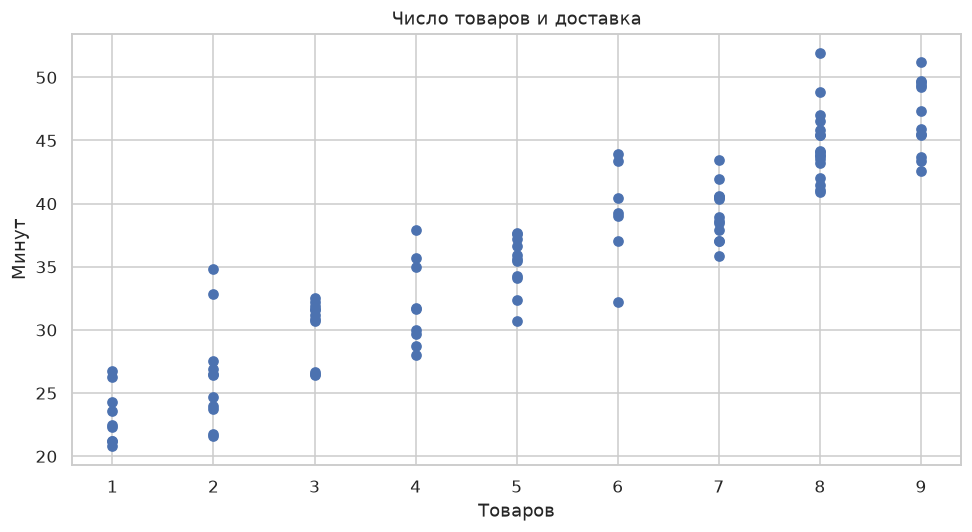

In [9]:
np.random.seed(42);items=np.random.randint(1,10,100)
correlated=20+3*items+np.random.normal(0,3,100)
r=np.corrcoef(items,correlated)[0,1];print('Pearson r:',r)
plt.scatter(items,correlated);plt.xlabel('Товаров');plt.ylabel('Минут');plt.title('Число товаров и доставка');show('correlation')

Связь сильная положительная: больше позиций может требовать больше времени на сборку. Из корреляции наблюдаемых данных причинность не следует: возможны смешивающие факторы, например размер склада или сложность заказа. В примере с мороженым общий фактор — жара/лето: растут покупки и число купающихся. Другой пример: рекламные расходы и выручка одновременно растут перед праздниками; сезонность мешает приписать весь прирост рекламе.

## 3.1 Bootstrap среднего

Среднее: 32.5 ; центральный 95% bootstrap ДИ: [29.16666667 37.66666667]


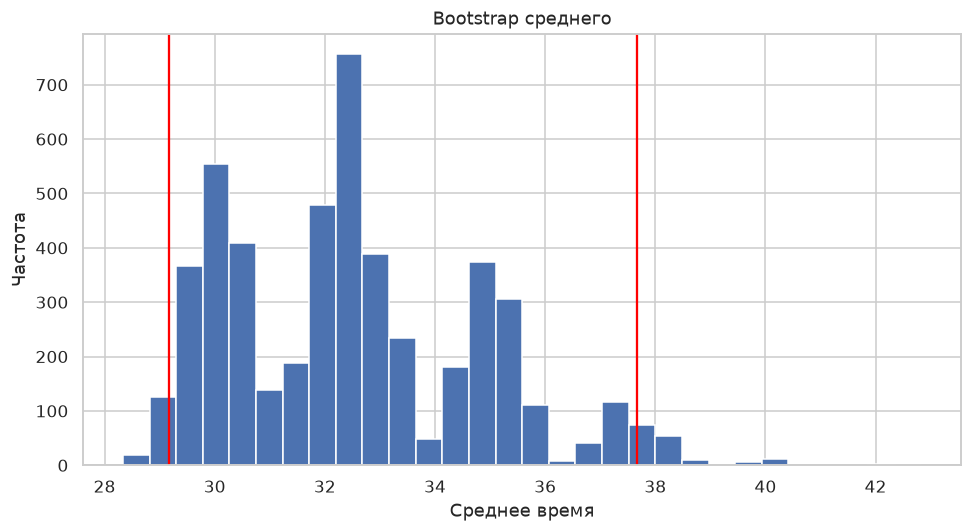

In [10]:
np.random.seed(42);x=np.array([28,31,29,45,32,30]);B=5000
means=np.empty(B)
for i in range(B):
    means[i]=np.random.choice(x,size=x.size,replace=True).mean()
ci=np.quantile(means,[.025,.975])
print('Среднее:',x.mean(),'; центральный 95% bootstrap ДИ:',ci)
plt.hist(means,bins=30);plt.axvline(ci[0],color='red');plt.axvline(ci[1],color='red');plt.title('Bootstrap среднего');plt.xlabel('Среднее время');plt.ylabel('Частота');show('bootstrap')

Выборка с возвращением имитирует новые выборки из эмпирического распределения. Без возвращения перестановка всех шести элементов не меняла бы среднее. Наблюдение 45 увеличивает правый хвост, особенно при многократном попадании. При n=6 эмпирическое распределение плохо описывает генеральное, поэтому ДИ нестабилен. Корректная частотная интерпретация: при многократном повторении процедуры около 95% построенных таким способом интервалов покрывают фиксированное истинное среднее; конкретному уже вычисленному интервалу вероятность истинности 95% не приписывается.

## 3.2 Гипотезы и ошибки
Обозначим эффект Δ=μB−μA. **H0: Δ≥0**, алгоритм не уменьшает среднее; **H1: Δ<0**. Для расчёта одностороннего критерия используется граничный случай Δ=0.

Ошибка I рода — объявить уменьшение, когда его нет; это ложная тревога, которая может привести к напрасным расходам 5 млн рублей в год. Ошибка II рода — не обнаружить реальное уменьшение; это пропущенный эффект и упущенная выгода.

## 3.3 p-value и решение
p-value — вероятность при H0 и выполненных предпосылках получить статистику не менее экстремальную в направлении альтернативы, чем наблюдаемая. Это не вероятность истинности H0. При p=0,001<0,05 результат статистически значим. Экономия всего трёх секунд при миллионе пользователей может быть статистически обнаружима, но не окупать 5 млн рублей.

Перед внедрением нужны величина эффекта и ДИ, стоимость сэкономленного времени, влияние на конверсию и жалобы, стабильность сегментов и расходы эксплуатации. Рекомендация — не внедрять только на основании p-value: сначала показать практически существенную выгоду и положительную экономику.

## Итоговый вопрос
Если среднее уменьшилось, разброс и p95 выросли, а p90 почти не изменился, уточню:
1. Качество данных: рандомизация, единые периоды, пропуски, сбои измерения, размеры групп, независимость наблюдений.
2. Размер эффекта: абсолютное и относительное изменение среднего с ДИ, заранее выбранная минимально полезная величина.
3. Распределение: гистограммы, сегменты городов и типов заказов, доля нарушений SLA.
4. Выбросы: технические ошибки или реальные задержки; результаты с ними и без них без произвольного удаления.
5. Процентили: ДИ для p90/p95/p99; сколько клиентов стало ждать дольше.
6. Значимость: корректность критерия, множественные проверки, отсутствие подглядывания в A/B-тест.
7. Практический эффект: ценность улучшения для типичного клиента и вред медленному хвосту.
8. Бизнес: чистая выгода после расходов, возвратов и поддержки; допустимость ухудшения SLA.
До ответа на эти вопросы полный запуск не обоснован.